#  Isolation Forest

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest

In [2]:
# Generate dense normal clusters plus isolated outliers
np.random.seed(42)

# 400 normal points in two blobs (imagine more hidden features in real use)
X_normal, _ = make_blobs(n_samples=400, centers=[[0, 0], [4, 4]],
                         cluster_std=0.7, random_state=42)

# 20 isolated outliers far from clusters
X_out = np.random.uniform(low=-4, high=8, size=(20, 2))

# Combine into one dataset
X_all = np.vstack([X_normal, X_out])

# Build DataFrame
df = pd.DataFrame(X_all, columns=["feature1", "feature2"])
print(df.shape)

(420, 2)


In [3]:
# Train Isolation Forest and predict outliers
# No scaling needed because splits are axis-based, not distance-based
model = IsolationForest(
    n_estimators=100,    # Number of isolation trees
    max_samples="auto",  # Samples per tree (auto = min(256, n))
    contamination=0.05,  # Expected outlier ratio: 5%
    random_state=42      # Fixed seed for reproducibility
)

# Fit and predict: 1 = inlier, -1 = outlier
labels = model.fit_predict(df[["feature1", "feature2"]])
df["iforest_label"] = labels
df["is_outlier"] = df["iforest_label"] == -1

# Anomaly score: lower score_samples means more abnormal
df["anomaly_score"] = model.score_samples(df[["feature1", "feature2"]])

print(f"Detected outliers: {df['is_outlier'].sum()}")
print(df.sort_values("anomaly_score").head(10))

Detected outliers: 21
     feature1  feature2  iforest_label  is_outlier  anomaly_score
405 -3.752986  7.638918             -1        True      -0.780648
416 -3.219381  7.386626             -1        True      -0.765374
403 -3.302997  6.394114             -1        True      -0.752027
417  7.587584  5.700768             -1        True      -0.718495
414  3.108975 -3.442595             -1        True      -0.711027
400  0.494481  7.408572             -1        True      -0.707531
406  5.989312 -1.451931             -1        True      -0.703849
402 -2.127776 -2.128066             -1        True      -0.683606
418 -0.344635 -2.827935             -1        True      -0.668215
410  3.342235 -2.326074             -1        True      -0.661014


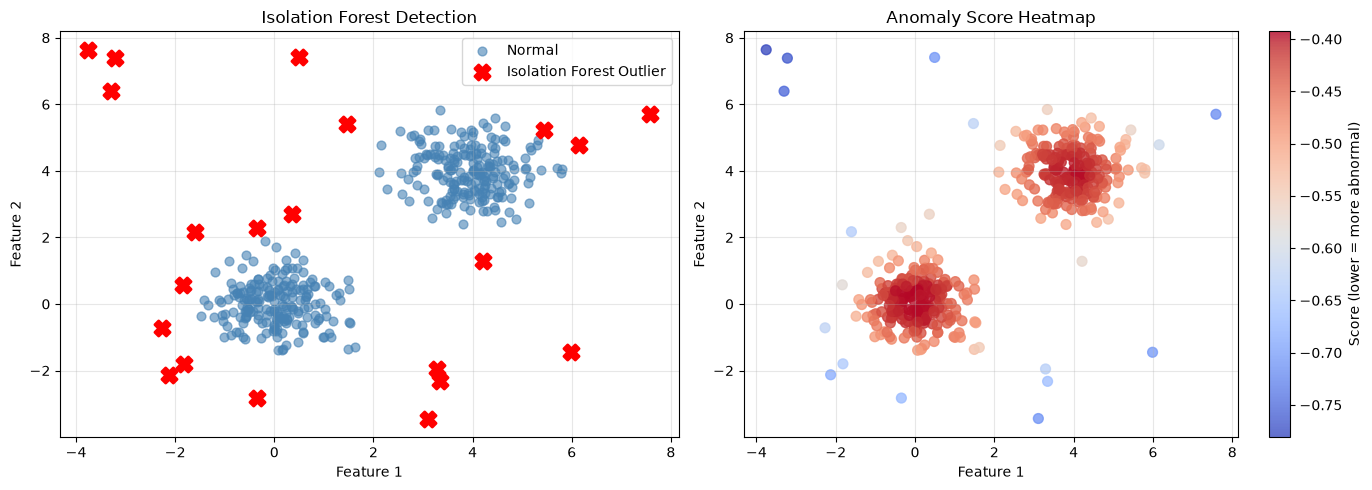

In [4]:
#  Visualize Isolation Forest results and score heatmap
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: normal points vs detected outliers
normal = df[~df["is_outlier"]]
outliers = df[df["is_outlier"]]
axes[0].scatter(normal["feature1"], normal["feature2"], color="steelblue", alpha=0.6, s=40, label="Normal")
axes[0].scatter(outliers["feature1"], outliers["feature2"], color="red", marker="X", s=120, linewidths=2, label="Isolation Forest Outlier", zorder=5)
axes[0].set_title("Isolation Forest Detection")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right plot: all points colored by anomaly score
scatter = axes[1].scatter(df["feature1"], df["feature2"], c=df["anomaly_score"], cmap="coolwarm", s=50, alpha=0.8)
plt.colorbar(scatter, ax=axes[1], label="Score (lower = more abnormal)")
axes[1].set_title("Anomaly Score Heatmap")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
# Experiment - try different contamination values
for c in [0.02, 0.05, 0.10]:
    temp_model = IsolationForest(n_estimators=100, contamination=c, random_state=42)
    temp_labels = temp_model.fit_predict(df[["feature1", "feature2"]])
    count = (temp_labels == -1).sum()
    print(f"contamination={c}: detected {count} outliers")

# Question: True injected outliers were 20 / 420 = 4.7%.
# Question: Which contamination value matches reality best? What happens with 0.10?

contamination=0.02: detected 9 outliers
contamination=0.05: detected 21 outliers
contamination=0.1: detected 42 outliers
